# 03 · Fitur harga (K1) dan teknikal (K2)

**Bab 3 Subbab 3.7.1–3.7.2.** Semua fitur dihitung **di dalam segmen** sehingga dimulai ulang setelah gap tak
terjelaskan, dan hanya memakai data sampai waktu keputusan $\tau_t$.

| Kelompok | Fitur |
|---|---|
| Harga (9) | $r_t, \dots, r_{t-5}$; $\ln(C_t/O_t)$; $\ln(H_t/L_t)$; $\sigma_{t,24}$ |
| Teknikal (4) | RSI 14 (Wilder); garis, sinyal, histogram MACD(12, 26, 9) dibagi $C_t$ |

K1 = harga. K2 = harga + teknikal.

**Pemanasan:** setelah awal data atau gap tak terjelaskan, observasi dipakai setelah sedikitnya 50 bar valid, yaitu
mulai **bar ke-51** dalam segmen.

**Input:** `01_harga.parquet`, `02_label.parquet` · **Output:** `03_fitur.parquet`

In [1]:
import tomllib
from pathlib import Path

# Cari folder proyek (folder yang memuat configs/phase4-p0.toml) agar notebook bisa dijalankan dari mana saja.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/phase4-p0.toml").exists())
CFG = tomllib.loads((ROOT / "configs/phase4-p0.toml").read_text(encoding="utf-8"))
OUT = ROOT / "data/interim/phase4-p0"     # folder hasil; diabaikan Git karena memuat data vendor
OUT.mkdir(parents=True, exist_ok=True)

## 1. RSI Wilder

- Perubahan $d_t = C_t - C_{t-1}$, kenaikan $g_t = \max(d_t, 0)$, penurunan $\ell_t = \max(-d_t, 0)$.
- Rata-rata awal = rata-rata aritmetika 14 perubahan pertama.
- Sesudahnya: $\bar g_t = (13\,\bar g_{t-1} + g_t)/14$, sama untuk $\bar\ell_t$.
- RSI $= 100 - 100/(1 + \bar g_t/\bar\ell_t)$; jika keduanya nol → 50; jika hanya $\bar\ell_t$ nol → 100.

In [2]:
import numpy as np
import pandas as pd


def rsi_wilder(close, n):
    hasil = np.full(len(close), np.nan)
    if len(close) <= n:
        return hasil
    beda = np.diff(close)
    naik, turun = np.maximum(beda, 0), np.maximum(-beda, 0)
    g, l = naik[:n].mean(), turun[:n].mean()

    def rsi(g, l):
        if g == 0 and l == 0:
            return 50.0
        if l == 0:
            return 100.0
        return 100 - 100 / (1 + g / l)

    hasil[n] = rsi(g, l)                       # RSI pertama ada di bar ke-(n+1)
    for i in range(n + 1, len(close)):
        g = ((n - 1) * g + naik[i - 1]) / n
        l = ((n - 1) * l + turun[i - 1]) / n
        hasil[i] = rsi(g, l)
    return hasil

### Contoh kecil yang bisa dicek dengan kalkulator

Lima belas harga penutupan → 14 perubahan → RSI pertama.

In [3]:
c = np.array([100, 101, 102, 101, 103, 104, 103, 105, 106, 105, 107, 108, 107, 109, 110.0])
d = np.diff(c)
g, l = np.maximum(d, 0).mean(), np.maximum(-d, 0).mean()
print("rata-rata kenaikan =", g, "· rata-rata penurunan =", l)
print("RSI manual =", 100 - 100 / (1 + g / l))
print("RSI fungsi =", rsi_wilder(c, 14)[14])

rata-rata kenaikan = 1.0 · rata-rata penurunan = 0.2857142857142857
RSI manual = 77.77777777777777
RSI fungsi = 77.77777777777777


## 2. EMA dan MACD

- EMA periode $p$: nilai awal = rata-rata $p$ penutupan pertama, lalu $\text{EMA}_t = \alpha C_t + (1-\alpha)\text{EMA}_{t-1}$, $\alpha = 2/(p+1)$.
- Garis MACD = EMA12 − EMA26. Sinyal = EMA9 dari garis MACD (diawali rata-rata 9 nilai MACD valid pertama).
- Histogram = garis − sinyal. Ketiganya dibagi $C_t$.

In [4]:
P = CFG["fitur"]


def ema(nilai, p):
    hasil = np.full(len(nilai), np.nan)
    if len(nilai) < p:
        return hasil
    hasil[p - 1] = nilai[:p].mean()
    alpha = 2 / (p + 1)
    for i in range(p, len(nilai)):
        hasil[i] = alpha * nilai[i] + (1 - alpha) * hasil[i - 1]
    return hasil


def macd(close):
    garis = ema(close, P["macd_fast"]) - ema(close, P["macd_slow"])
    sinyal = np.full(len(close), np.nan)
    valid = np.flatnonzero(np.isfinite(garis))
    sinyal[valid] = ema(garis[valid], P["macd_signal"])
    return garis, sinyal, garis - sinyal

## 3. Hitung fitur per segmen

In [5]:
harga = pd.read_parquet(OUT / "01_harga.parquet")
label = pd.read_parquet(OUT / "02_label.parquet")
df = harga.merge(label, on=["time", "segment_id"], validate="1:1")


def fitur_segmen(seg):
    c = seg["close"].to_numpy()
    f = pd.DataFrame(index=seg.index)
    for lag in range(6):
        f[f"return_lag_{lag}"] = seg["r"].shift(lag)
    f["log_close_open"] = np.log(seg["close"] / seg["open"])
    f["log_high_low"] = np.log(seg["high"] / seg["low"])
    f["sigma_24"] = seg["sigma_24"]
    f["rsi_14"] = rsi_wilder(c, P["rsi_period"])
    garis, sinyal, hist = macd(c)
    f["macd_line_norm"] = garis / c
    f["macd_signal_norm"] = sinyal / c
    f["macd_hist_norm"] = hist / c
    f["bar_ke"] = np.arange(1, len(seg) + 1)      # nomor bar di dalam segmen, mulai 1
    return f


fitur = pd.concat(fitur_segmen(seg) for _, seg in df.groupby("segment_id"))
K1 = P["k1"]
K2 = K1 + P["teknikal"]
assert list(fitur.columns[:13]) == K2

# Bar ke berapa setiap fitur pertama kali tersedia di segmen pertama:
pertama = {k: int(fitur.loc[fitur[k].notna(), "bar_ke"].min()) for k in K2}
pd.Series(pertama, name="bar pertama tersedia").to_frame()

,bar pertama tersedia
return_lag_0,2
return_lag_1,3
return_lag_2,4
return_lag_3,5
return_lag_4,6
return_lag_5,7
log_close_open,1
log_high_low,1
sigma_24,25
rsi_14,15


Semua indikator sudah tersedia jauh sebelum bar ke-51 (yang paling lambat adalah sinyal MACD di bar ke-34). Syarat
pemanasan 50 bar tetap dipakai sesuai Bab 3.

In [6]:
fitur["fitur_layak"] = (fitur["bar_ke"] >= P["first_usable_segment_bar"]) & fitur[K2].notna().all(axis=1)
assert fitur.loc[fitur["fitur_layak"], K2].notna().all().all()
print("Bar dengan fitur layak:", int(fitur["fitur_layak"].sum()), "dari", len(fitur))
print("Bar terbuang oleh pemanasan:", int((fitur["bar_ke"] < P["first_usable_segment_bar"]).sum()),
      "(", harga["segment_id"].nunique(), "segmen × 50 bar )")
fitur.loc[fitur["fitur_layak"], K2].describe().T[["mean", "std", "min", "max"]]

Bar dengan fitur layak: 38333 dari 38799
Bar terbuang oleh pemanasan: 466 ( 10 segmen × 50 bar )


,mean,std,min,max
return_lag_0,2.710982e-05,0.002343,-0.058846,0.026851
return_lag_1,2.692932e-05,0.002343,-0.058846,0.026851
return_lag_2,2.708471e-05,0.002343,-0.058846,0.026851
return_lag_3,2.708059e-05,0.002343,-0.058846,0.026851
return_lag_4,2.706004e-05,0.002343,-0.058846,0.026851
return_lag_5,2.670846e-05,0.002343,-0.058846,0.026851
log_close_open,2.555842e-05,0.002311,-0.058846,0.026891
log_high_low,2.980539e-03,0.002572,0.000000,0.075300
sigma_24,2.015841e-03,0.001196,0.000486,0.016320
rsi_14,5.147665e+01,12.712603,9.136374,93.139683


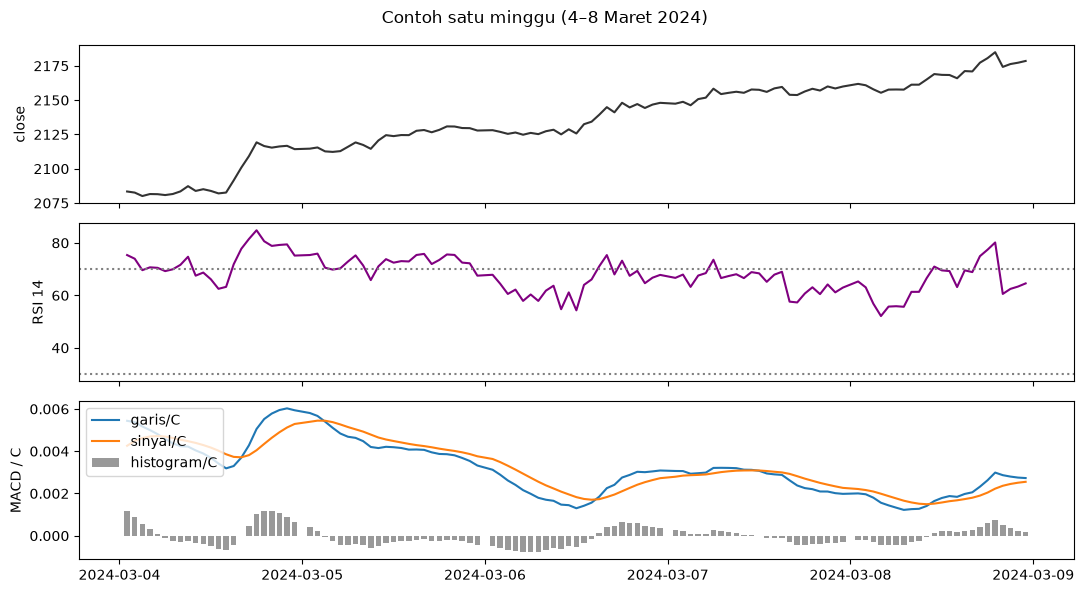

In [7]:
import matplotlib.pyplot as plt

minggu = df[(df["time"] >= "2024-03-04") & (df["time"] < "2024-03-09")].index
fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
ax[0].plot(df.loc[minggu, "time"], df.loc[minggu, "close"], color="0.2")
ax[0].set_ylabel("close")
ax[1].plot(df.loc[minggu, "time"], fitur.loc[minggu, "rsi_14"], color="purple")
ax[1].axhline(70, ls=":", c="gray")
ax[1].axhline(30, ls=":", c="gray")
ax[1].set_ylabel("RSI 14")
ax[2].plot(df.loc[minggu, "time"], fitur.loc[minggu, "macd_line_norm"], label="garis/C")
ax[2].plot(df.loc[minggu, "time"], fitur.loc[minggu, "macd_signal_norm"], label="sinyal/C")
ax[2].bar(df.loc[minggu, "time"], fitur.loc[minggu, "macd_hist_norm"], width=0.03, color="0.6", label="histogram/C")
ax[2].legend(loc="upper left")
ax[2].set_ylabel("MACD / C")
fig.suptitle("Contoh satu minggu (4–8 Maret 2024)")
plt.tight_layout()

In [8]:
fitur.insert(0, "time", df["time"])
fitur.to_parquet(OUT / "03_fitur.parquet", index=False)
print("Tersimpan:", (OUT / "03_fitur.parquet").relative_to(ROOT), fitur.shape)

Tersimpan: data/interim/phase4-p0/03_fitur.parquet (38799, 16)
